# Lab 3 (Parcial 2) · Parte III — Siguiente carácter con LSTM y GRU

## Objetivo

Repetir el problema de la Parte II del Lab 2 (**predecir el siguiente carácter** de *The Time Machine* tras leer 20 caracteres) con modelos **LSTM** y **GRU optimizados**, y comparar su **perplejidad** con la de la RNN *vanilla*.

Para que la comparación sea justa se mantiene **todo** lo que fijaba el Lab 2:

* mismo texto corregido (26 letras + espacio + un único `_` como desconocido: 28 símbolos);
* entradas **one-hot** (sin embeddings);
* ventanas de **20 caracteres**;
* partición **en orden** 30 % entrenamiento / 10 % validación / 60 % test;
* la misma evaluación: el carácter 21 tras leer los 20 anteriores;
* el mismo protocolo: experimentos acumulativos con 3 semillas en validación y **20 ejecuciones finales**.

Resultado de referencia del Lab 2 (RNN *vanilla* optimizada, 20 ejecuciones): **49,46 % ± 0,24 %** de exactitud y **perplejidad 5,96 ± 0,10** en test.

## 0. Preparación del entorno

El texto es el mismo `timemachine.txt` (copiado en `data/`; si no está, se descarga del servidor de d2l).

**Dispositivo.** Cada arquitectura se entrena donde es más rápida en un Mac con chip M3: la **LSTM en la GPU (MPS)**, que tiene un núcleo optimizado para ella, y la **RNN y la GRU en la CPU** (en MPS la GRU no tiene ese núcleo y no gana nada). Al final se mide el coste de las tres en igualdad de condiciones (CPU).

In [1]:
%matplotlib inline
import collections
import copy
import json
import math
import os
import re
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

LAB_DIR = None
for candidato in (Path.cwd(), Path.cwd() / 'lab3', Path.cwd() / 'Parcial-2' / 'Lab3-LSTM' / 'lab3', Path('/content')):
    if (candidato / 'data').exists() or (candidato / 'IMDB Dataset10M.csv').exists():
        LAB_DIR = candidato
        break
if LAB_DIR is None:
    raise FileNotFoundError('No se encuentra la carpeta del Lab 3 (con data/)')
DATA_DIR = LAB_DIR / 'data' if (LAB_DIR / 'data').exists() else LAB_DIR

RUTA_TEXTO = DATA_DIR / 'timemachine.txt'
if not RUTA_TEXTO.exists():
    urllib.request.urlretrieve('http://d2l-data.s3-accelerate.amazonaws.com/timemachine.txt', RUTA_TEXTO)

MPS = torch.backends.mps.is_available()
DISPOSITIVO = {'RNN': torch.device('cpu'), 'GRU': torch.device('cpu'),
               'LSTM': torch.device('mps') if MPS else torch.device('cpu')}
torch.set_num_threads(min(4, os.cpu_count()))
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.precision', 4)
print('PyTorch', torch.__version__, '| dispositivos:', {k: str(v) for k, v in DISPOSITIVO.items()})

PyTorch 2.15.0 | dispositivos: {'RNN': 'cpu', 'GRU': 'cpu', 'LSTM': 'mps'}


# 1. Datos: exactamente los del Lab 2

Mismo preprocesado corregido del Lab 2: minúsculas, cualquier secuencia de blancos (incluidos los saltos de línea) pasa a un espacio y todo lo que no sea una letra o el espacio se convierte en `_`. Ventanas de 21 caracteres: los 20 primeros son la entrada `X` y los mismos desplazados una posición, el objetivo `Y` (`Y[:, -1]` es el carácter siguiente a la ventana).

In [2]:
raw_text = RUTA_TEXTO.read_text(encoding='utf-8')
PERMITIDOS = set('abcdefghijklmnopqrstuvwxyz ')

def preprocesar(texto):
    texto = re.sub(r'\s+', ' ', texto.lower())
    return ''.join(c if c in PERMITIDOS else '_' for c in texto)

texto = preprocesar(raw_text)
vocab = sorted(set(texto)); V = len(vocab)
c2i = {c: i for i, c in enumerate(vocab)}; i2c = dict(enumerate(vocab))
ids = torch.tensor([c2i[c] for c in texto])
n = len(ids); n_tr = int(0.3 * n); n_va = n_tr + int(0.1 * n)

def ventanas(t, L=20):
    w = t.unfold(0, L + 1, 1)
    return w[:, :L].contiguous(), w[:, 1:].contiguous()

(Xtr, Ytr), (Xva, Yva), (Xte, Yte) = (ventanas(t) for t in (ids[:n_tr], ids[n_tr:n_va], ids[n_va:]))
print(f'texto: {n} caracteres | vocabulario ({V}): {"".join(vocab)!r}')
print(f'ventanas -> entrenamiento {len(Xtr)}, validación {len(Xva)}, test {len(Xte)}')
print('ejemplo:', repr(''.join(i2c[int(i)] for i in Xtr[100])), '->', repr(i2c[int(Ytr[100, -1])]))

ref_lab2 = None
for ruta in (LAB_DIR.parent.parent / 'Lab-2-Recurrent-Neural-Networks' / 'Lab-2' / 'resultados_lab2_caracteres.json',):
    if ruta.exists():
        ref_lab2 = json.loads(ruta.read_text(encoding='utf-8'))
        print('Referencia del Lab 2 (RNN, 20 ejecuciones): exactitud', f"{ref_lab2['final20']['acc_media']:.2%}",
              '| perplejidad', f"{ref_lab2['final20']['pp_media']:.3f}", '| configuración:', ref_lab2['config_final'])

texto: 178606 caracteres | vocabulario (28): ' _abcdefghijklmnopqrstuvwxyz'
ventanas -> entrenamiento 53561, validación 17840, test 107145
ejemplo: 'of him_ was expoundi' -> 'n'
Referencia del Lab 2 (RNN, 20 ejecuciones): exactitud 49.46% | perplejidad 5.964 | configuración: {'h': 256, 'activacion': 'tanh', 'dropout': 0.0, 'init': 'he', 'optimizador': 'adam', 'lr': 0.01, 'clip': 0.25, 'todas_posiciones': True, 'bs': 128, 'max_epocas': 40, 'paciencia': 5, 'reducir_lr': True}


# 2. Un modelo recurrente para las tres arquitecturas

`RedRecurrente` es la misma red del Lab 2 con la capa recurrente intercambiable: one-hot → `nn.RNN` / `nn.LSTM` / `nn.GRU` (una o varias capas) → dropout → capa lineal con un logit por carácter en **cada** posición. Opciones:

* `init`: `'defecto'` (la de PyTorch: uniforme en $[-1/\sqrt h,\,1/\sqrt h]$) o `'he'` (la que ganó en el Lab 2 para la RNN);
* `dropout`: sobre los estados ocultos antes de la capa de salida (y entre capas si hay varias);
* `sesgo_olvido`: valor inicial del sesgo de la puerta de olvido de la LSTM (PyTorch lo pone aleatorio cerca de 0).

**Número de parámetros.** Con $i = 28$ entradas y $h$ unidades, la capa recurrente tiene $h(i+h+2)$ parámetros en la RNN, $3h(i+h+2)$ en la GRU y $4h(i+h+2)$ en la LSTM (PyTorch usa dos sesgos por bloque); la capa de salida añade $hV + V$.

In [3]:
class RedRecurrente(nn.Module):
    def __init__(self, tipo, h, capas=1, dropout=0.0, init='defecto', sesgo_olvido=None):
        super().__init__()
        extra = {'nonlinearity': 'tanh'} if tipo == 'RNN' else {}
        self.rnn = getattr(nn, tipo)(V, h, num_layers=capas, batch_first=True,
                                     dropout=dropout if capas > 1 else 0.0, **extra)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(h, V)
        if init == 'he':
            for nombre, p in self.rnn.named_parameters():
                if 'bias' in nombre:
                    nn.init.zeros_(p)
                else:
                    nn.init.kaiming_uniform_(p, nonlinearity='relu')
        if sesgo_olvido is not None and tipo == 'LSTM':
            for nombre, p in self.rnn.named_parameters():
                if 'bias' in nombre:                     # orden de PyTorch: entrada, olvido, celda, salida
                    p.data[h:2 * h] = sesgo_olvido / 2   # bias_ih + bias_hh = sesgo_olvido

    def forward(self, x):                                # x: (B, T) índices
        H, _ = self.rnn(F.one_hot(x, V).float())        # (B, T, h)
        return self.fc(self.dropout(H))                  # (B, T, V) logits en cada posición


def contar(m):
    return sum(p.numel() for p in m.parameters())

h = 256
tabla_params = pd.DataFrame({tipo: {'capa recurrente': contar(RedRecurrente(tipo, h).rnn),
                                    'fórmula': {'RNN': 1, 'GRU': 3, 'LSTM': 4}[tipo] * h * (V + h + 2),
                                    'total (con la capa de salida)': contar(RedRecurrente(tipo, h))}
                             for tipo in ('RNN', 'GRU', 'LSTM')}).T
display(tabla_params)

,capa recurrente,fórmula,total (con la capa de salida)
RNN,73216,73216,80412
GRU,219648,219648,226844
LSTM,292864,292864,300060


## 2.1. Entrenamiento y evaluación

`entrenar()` es la del Lab 2 con el tipo de red como parámetro: minilotes, pérdida en las 20 posiciones (cada prefijo predice su siguiente carácter), recorte del gradiente, tasa que se reduce a la mitad cuando la validación no mejora (`ReduceLROnPlateau`) y **parada temprana** con la pérdida de validación, quedándose con el mejor modelo. La evaluación siempre es la de la tarea: el carácter 21.

**Criterio para elegir hiperparámetros.** En esta parte el enunciado pide la **perplejidad**, así que las opciones se comparan por la **pérdida media en validación** (la perplejidad es su exponencial) y la exactitud se muestra al lado. Es el mismo criterio que usa la parada temprana.

In [4]:
def evaluar(modelo, X, Y, bs=4096):
    disp = next(modelo.parameters()).device
    modelo.eval(); perdida, aciertos = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            logits = modelo(X[i:i + bs].to(disp))[:, -1]
            y = Y[i:i + bs, -1].to(disp)
            perdida += F.cross_entropy(logits, y, reduction='sum').item()
            aciertos += (logits.argmax(-1) == y).sum().item()
    modelo.train()
    return perdida / len(X), aciertos / len(X)


def entrenar(tipo='RNN', h=256, capas=1, dropout=0.0, init='he', sesgo_olvido=None, lr=0.01, wd=0.0, bs=128,
             clip=0.25, max_epocas=40, paciencia=5, reducir_lr=True, semilla=0, epocas_fijas=None):
    disp = DISPOSITIVO[tipo]
    torch.manual_seed(semilla)
    modelo = RedRecurrente(tipo, h, capas, dropout, init, sesgo_olvido).to(disp)
    opt = optim.Adam(modelo.parameters(), lr=lr, weight_decay=wd)
    planificador = optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=1) if reducir_lr else None
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    mejor, estado, sin_mejora, inicio = np.inf, None, 0, time.time()
    for epoca in range(epocas_fijas or max_epocas):
        orden = torch.randperm(len(Xtr)); suma = 0.0
        for i in range(0, len(Xtr), bs):
            j = orden[i:i + bs]
            logits = modelo(Xtr[j].to(disp))
            loss = F.cross_entropy(logits.reshape(-1, V), Ytr[j].reshape(-1).to(disp))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), clip)
            opt.step()
            suma += loss.item() * len(j)
        vl, va = evaluar(modelo, Xva, Yva)
        hist['train_loss'].append(suma / len(Xtr)); hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if planificador is not None:
            planificador.step(vl)
        if vl < mejor:
            mejor, estado, sin_mejora = vl, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if epocas_fijas is None and sin_mejora >= paciencia:
                break
    modelo.load_state_dict(estado)
    mejor_ep = int(np.argmin(hist['val_loss'])) + 1
    return modelo, {'hist': hist, 'mejor_epoca': mejor_ep, 'epocas': len(hist['val_loss']),
                    'val_loss': hist['val_loss'][mejor_ep - 1], 'val_acc': hist['val_acc'][mejor_ep - 1],
                    'segundos': time.time() - inicio, 'parametros': contar(modelo)}


SEMILLAS = (0, 1, 2)
_cache = {}

def probar(nombre, variantes, base):
    """Cada variante (cambios sobre 'base') con 3 semillas; se elige la de menor perplejidad media en validación.
    Cada experimento repite la ganadora del anterior: esos entrenamientos se reutilizan en lugar de repetirlos."""
    filas = []
    for etiqueta, cambios in variantes.items():
        cfg = base | cambios
        res = []
        for s in SEMILLAS:
            clave = (tuple(sorted(cfg.items())), s)
            if clave not in _cache:
                _cache[clave] = entrenar(**cfg, semilla=s)[1]
            res.append(_cache[clave])
        filas.append({nombre: etiqueta,
                      'val_pp': np.mean([math.exp(r['val_loss']) for r in res]),
                      'val_acc': np.mean([r['val_acc'] for r in res]), 'std_acc': np.std([r['val_acc'] for r in res]),
                      'mejor_época': np.mean([r['mejor_epoca'] for r in res]),
                      'train_loss (mejor época)': np.mean([r['hist']['train_loss'][r['mejor_epoca'] - 1] for r in res]),
                      's/época': np.mean([r['segundos'] / r['epocas'] for r in res])})
    df = pd.DataFrame(filas).set_index(nombre)
    mejor = df['val_pp'].idxmin()
    return df, base | variantes[mejor], mejor

# 3. Primer intento: cambiar la RNN por una LSTM o una GRU sin más

Se toma la **configuración final de la RNN del Lab 2** (256 unidades, inicialización He, sin dropout, Adam 0,01 con reducción, recorte 0,25, minilotes de 128) y solo se cambia el tipo de capa recurrente.

,val_pp,val_acc,std_acc,mejor_época,train_loss (mejor época),s/época
arquitectura (config. de la RNN),,,,,,
RNN,5.8913,0.4922,0.0035,7.3333,1.3215,5.1609
LSTM,6.2834,0.4872,0.0009,1.0000,1.5267,8.5130
GRU,6.4792,0.4891,0.0010,1.0000,1.4634,27.6834


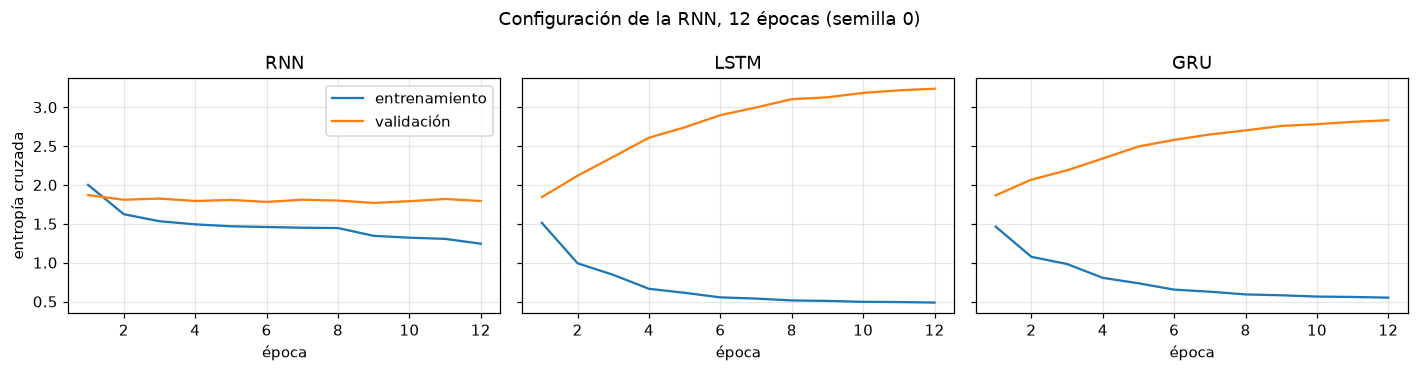

In [5]:
CONFIG_RNN = dict(tipo='RNN', h=256, capas=1, dropout=0.0, init='he', lr=0.01, clip=0.25, bs=128,
                  max_epocas=40, paciencia=5, reducir_lr=True)
exp0, _, _ = probar('arquitectura (config. de la RNN)', {t: dict(tipo=t) for t in ('RNN', 'LSTM', 'GRU')}, CONFIG_RNN)
display(exp0)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for k, tipo in enumerate(('RNN', 'LSTM', 'GRU')):
    _, info = entrenar(**(CONFIG_RNN | dict(tipo=tipo)), semilla=0, epocas_fijas=12)
    ep = np.arange(1, 13)
    ax[k].plot(ep, info['hist']['train_loss'], label='entrenamiento'); ax[k].plot(ep, info['hist']['val_loss'], label='validación')
    ax[k].set_title(tipo); ax[k].set_xlabel('época')
ax[0].set_ylabel('entropía cruzada'); ax[0].legend(); plt.suptitle('Configuración de la RNN, 12 épocas (semilla 0)')
plt.tight_layout(); plt.show()

**Cambiar sin más la RNN por una LSTM o una GRU empeora el resultado** (validación, 3 semillas):

| Arquitectura | Perplejidad | Exactitud | Mejor época | s/época |
|---|---|---|---|---|
| RNN | **5,89** | **49,2 %** | 7,3 | 5,2 (CPU) |
| LSTM | 6,28 | 48,7 % | **1** | 8,5 (MPS) |
| GRU | 6,48 | 48,9 % | **1** | 27,7 (CPU) |

La LSTM y la GRU alcanzan su mejor validación **en la primera época** y después solo sobreajustan. Tienen 3–4 veces más parámetros (300 060 y 226 844 frente a 80 412) y mucha más facilidad para memorizar. Y una época es mucho: con ventanas solapadas y 20 objetivos por ventana, cada época son ≈ 1 millón de predicciones sobre un texto de 53 000 caracteres, unas 20 pasadas. **Con 53 000 caracteres de entrenamiento, el reto de las redes con puertas es regularizar**, no recordar más.

# 4. Optimización de la LSTM y la GRU

Mismo método que en el Lab 2: experimentos **acumulativos**, cada opción con 3 semillas, se elige por perplejidad en validación y la ganadora pasa al siguiente. Se optimizan las dos arquitecturas por separado, con la misma lista de experimentos.

In [6]:
EXPERIMENTOS = [
    ('inicialización', lambda c: {'He (la de la RNN)': dict(init='he'), 'defecto de PyTorch': dict(init='defecto')}),
    ('dropout', lambda c: {d: dict(dropout=d) for d in (0.0, 0.25, 0.5)}),
    ('tasa (Adam)', lambda c: {lr: dict(lr=lr) for lr in (0.003, 0.01)}),
    ('neuronas ocultas', lambda c: {h: dict(h=h) for h in (128, 256, 512)}),
    ('capas', lambda c: {1: dict(capas=1), 2: dict(capas=2)}),
]
optimizacion, configs = {}, {}
for tipo in ('LSTM', 'GRU'):
    cfg = CONFIG_RNN | dict(tipo=tipo)
    inicio = time.time()
    for nombre, variantes in EXPERIMENTOS:
        df, cfg, mejor = probar(nombre, variantes(cfg), cfg)
        optimizacion[(tipo, nombre)] = df
        print(f'{tipo} · {nombre}: elegido {mejor!r}')
        display(df)
    if tipo == 'LSTM':
        df, cfg, mejor = probar('sesgo de la puerta de olvido', {'aleatorio (≈ 0)': dict(sesgo_olvido=None),
                                                                 '1': dict(sesgo_olvido=1.0)}, cfg)
        optimizacion[(tipo, 'sesgo de olvido')] = df
        print(f'{tipo} · sesgo de olvido: elegido {mejor!r}'); display(df)
    configs[tipo] = cfg
    print(f'== {tipo} optimizada en {time.time() - inicio:.0f} s:', cfg)

LSTM · inicialización: elegido 'defecto de PyTorch'


,val_pp,val_acc,std_acc,mejor_época,train_loss (mejor época),s/época
inicialización,,,,,,
He (la de la RNN),6.2834,0.4872,0.0009,1.0,1.5267,8.5130
defecto de PyTorch,5.9086,0.4954,0.0021,1.0,1.6673,8.7694


LSTM · dropout: elegido np.float64(0.5)


,val_pp,val_acc,std_acc,mejor_época,train_loss (mejor época),s/época
dropout,,,,,,
0.00,5.9086,0.4954,0.0021,1.0,1.6673,8.7694
0.25,5.3547,0.5051,0.0040,1.0,1.7590,7.6023
0.50,5.1507,0.5074,0.0007,1.0,1.8557,7.3070


LSTM · tasa (Adam): elegido np.float64(0.01)


,val_pp,val_acc,std_acc,mejor_época,train_loss (mejor época),s/época
tasa (Adam),,,,,,
0.003,5.6001,0.4868,0.0004,2.0,1.6155,7.620
0.010,5.1507,0.5074,0.0007,1.0,1.8557,7.307


... (14 outputs left out)

,val_pp,val_acc,std_acc,mejor_época,train_loss (mejor época),s/época
neuronas ocultas,,,,,,
128,5.1803,0.5081,0.0004,6.0000,1.4976,9.1485
256,5.2864,0.5014,0.0035,1.3333,1.6892,13.2914
512,5.2867,0.5033,0.0029,1.0000,1.7976,35.9622


GRU · capas: elegido 2


,val_pp,val_acc,std_acc,mejor_época,train_loss (mejor época),s/época
capas,,,,,,
1,5.1803,0.5081,0.0004,6.0,1.4976,9.1485
2,5.1409,0.5135,0.0035,4.0,1.6121,11.1844


== GRU optimizada en 2296 s: {'tipo': 'GRU', 'h': 128, 'capas': 2, 'dropout': 0.5, 'init': 'defecto', 'lr': 0.01, 'clip': 0.25, 'bs': 128, 'max_epocas': 40, 'paciencia': 5, 'reducir_lr': True}


**Resultados de la optimización** (perplejidad media en validación, 3 semillas):

| Paso | LSTM | GRU |
|---|---|---|
| configuración de la RNN (inicialización He) | 6,28 | 6,48 |
| inicialización por defecto de PyTorch | 5,91 | 6,16 |
| dropout 0,5 | 5,15 | 5,29 |
| tasa 0,01 (frente a 0,003) | 5,15 | 5,29 |
| neuronas ocultas | 5,14 (h = 512) | 5,18 (h = 128) |
| 2 capas | 4,92 | **5,14** |
| sesgo de olvido 1 (solo LSTM) | **4,90** | — |

* **El dropout es lo que más pesa** en las dos (rango de 0,76 y 0,87 en perplejidad): el problema era el sobreajuste. Con 0,5 la red tarda más en memorizar.
* **La inicialización He**, que era la mejor para la RNN, **perjudica** a las redes con puertas (+0,3–0,4 de perplejidad). Está pensada para ReLU; en la LSTM y la GRU las puertas usan sigmoide y tanh, y la inicialización por defecto (uniforme en $\pm1/\sqrt h$) les va mejor.
* La **tasa 0,003** es peor que 0,01 (5,60 frente a 5,15 en la LSTM): con tasa baja la red tarda más en llegar al punto en que empieza a sobreajustar, y ese punto es peor.
* **El tamaño oculto apenas importa.** La LSTM elige 512 por 0,006 de perplejidad, una diferencia dentro del ruido, a cambio de ser el doble de lenta. La GRU elige 128 (5,18 frente a 5,29). Con 128 unidades la mejor época se retrasa (6 en la GRU, 3,7 en la LSTM, frente a 1 con 256 o 512): una red más pequeña memoriza más despacio.
* **La segunda capa** ayuda a las dos, sobre todo a la LSTM (−0,22).
* **El sesgo de olvido 1 no cambia nada** (4,90 frente a 4,92): con ventanas de 20 caracteres no hay dependencias largas que proteger, al contrario que en la Parte I.
* **Configuraciones finales:**
  * LSTM: 2 capas de 512, dropout 0,5, inicialización por defecto, sesgo de olvido 1;
  * GRU: 2 capas de 128, dropout 0,5, inicialización por defecto;
  * las dos con Adam 0,01 que se reduce en las mesetas, recorte 0,25 y lotes de 128.

In [7]:
resumen = pd.concat({f'{t} · {e}': df for (t, e), df in optimizacion.items()}, names=['experimento', 'opción'])
rangos = resumen.groupby(level=0, sort=False)['val_pp'].agg(['min', 'max'])
rangos['rango de perplejidad'] = rangos['max'] - rangos['min']
display(rangos)
CONFIGS_FINALES = {'RNN': CONFIG_RNN, 'LSTM': configs['LSTM'], 'GRU': configs['GRU']}
for t, c in CONFIGS_FINALES.items():
    print(f'{t:5}', c)

,min,max,rango de perplejidad
experimento,,,
LSTM · inicialización,5.9086,6.2834,0.3748
LSTM · dropout,5.1507,5.9086,0.7579
LSTM · tasa (Adam),5.1507,5.6001,0.4494
LSTM · neuronas ocultas,5.1445,5.1732,0.0287
LSTM · capas,4.9219,5.1445,0.2226
LSTM · sesgo de olvido,4.9033,4.9219,0.0186
GRU · inicialización,6.1551,6.4792,0.3241
GRU · dropout,5.2864,6.1551,0.8687
GRU · tasa (Adam),5.2864,5.5598,0.2734


RNN   {'tipo': 'RNN', 'h': 256, 'capas': 1, 'dropout': 0.0, 'init': 'he', 'lr': 0.01, 'clip': 0.25, 'bs': 128, 'max_epocas': 40, 'paciencia': 5, 'reducir_lr': True}
LSTM  {'tipo': 'LSTM', 'h': 512, 'capas': 2, 'dropout': 0.5, 'init': 'defecto', 'lr': 0.01, 'clip': 0.25, 'bs': 128, 'max_epocas': 40, 'paciencia': 5, 'reducir_lr': True, 'sesgo_olvido': 1.0}
GRU   {'tipo': 'GRU', 'h': 128, 'capas': 2, 'dropout': 0.5, 'init': 'defecto', 'lr': 0.01, 'clip': 0.25, 'bs': 128, 'max_epocas': 40, 'paciencia': 5, 'reducir_lr': True}


# 5. 20 ejecuciones de cada arquitectura

Con su mejor configuración, cada arquitectura se entrena **20 veces** (semillas 100–119, como en el Lab 2), **12 épocas** cada vez para poder promediar las curvas (la mejor época está siempre antes), y se evalúa en test el modelo de la época con menor pérdida de validación. La RNN se vuelve a entrenar aquí con su configuración del Lab 2 para que las tres se midan con exactamente el mismo código.

In [8]:
EPOCAS_FINAL = 12
finales, modelos_ref = {}, {}
for tipo, cfg in CONFIGS_FINALES.items():
    inicio = time.time(); filas = []
    for s in range(100, 120):
        m, info = entrenar(**(cfg | dict(epocas_fijas=EPOCAS_FINAL)), semilla=s)
        tl, ta = evaluar(m, Xte, Yte)
        filas.append({'semilla': s, 'mejor_época': info['mejor_epoca'], 'val_acc': info['val_acc'],
                      'test_acc': ta, 'test_pp': math.exp(tl), 's/época': info['segundos'] / info['epocas'],
                      'hist': info['hist']})
        if s == 100:
            modelos_ref[tipo] = m
    finales[tipo] = filas
    print(f'{tipo}: 20 ejecuciones en {time.time() - inicio:.0f} s')

resumen20 = pd.DataFrame({tipo: {
    'exactitud test (media)': np.mean([f['test_acc'] for f in filas]),
    'exactitud test (desv.)': np.std([f['test_acc'] for f in filas], ddof=1),
    'perplejidad test (media)': np.mean([f['test_pp'] for f in filas]),
    'perplejidad test (desv.)': np.std([f['test_pp'] for f in filas], ddof=1),
    'mejor época (media)': np.mean([f['mejor_época'] for f in filas]),
    'parámetros': contar(modelos_ref[tipo]),
    's/época (su dispositivo)': np.mean([f['s/época'] for f in filas])} for tipo, filas in finales.items()}).T
display(resumen20)

RNN: 20 ejecuciones en 818 s


LSTM: 20 ejecuciones en 6338 s


GRU: 20 ejecuciones en 1747 s


,exactitud test (media),exactitud test (desv.),perplejidad test (media),perplejidad test (desv.),mejor época (media),parámetros,s/época (su dispositivo)
RNN,0.4946,0.0024,5.9645,0.0977,6.1,80412.0,3.2416
LSTM,0.5234,0.0056,4.9385,0.0536,1.3,3225628.0,25.3745
GRU,0.5142,0.0034,5.1925,0.0236,5.1,163356.0,7.0139


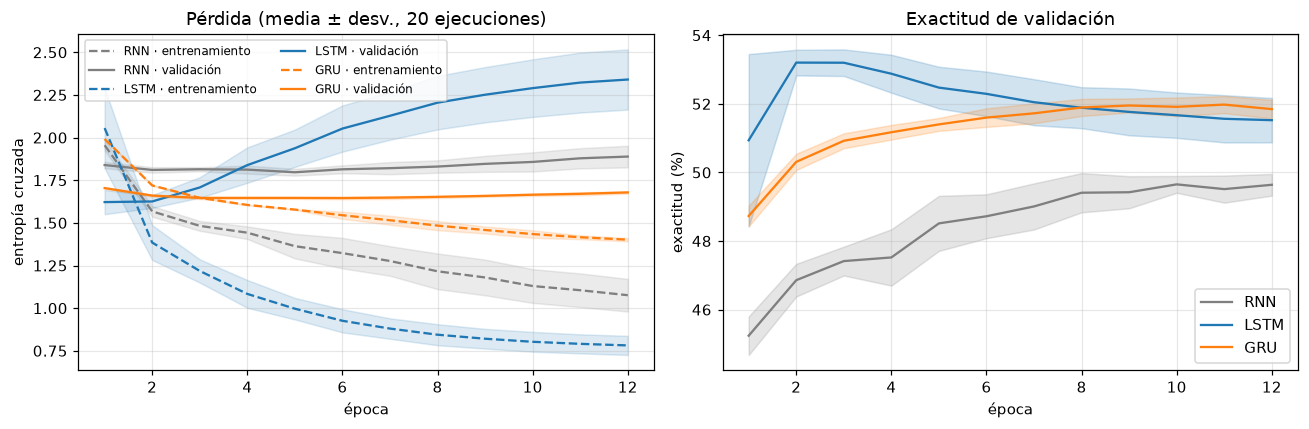

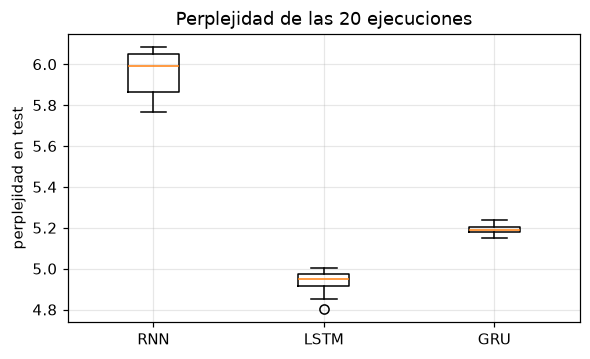

In [9]:
colores = {'RNN': 'tab:gray', 'LSTM': 'tab:blue', 'GRU': 'tab:orange'}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ep = np.arange(1, EPOCAS_FINAL + 1)
for tipo, filas in finales.items():
    for clave, estilo in (('train_loss', '--'), ('val_loss', '-')):
        c = np.array([f['hist'][clave] for f in filas]); mu, sd = c.mean(0), c.std(0)
        ax[0].plot(ep, mu, estilo, color=colores[tipo], label=f'{tipo} · {"entrenamiento" if clave == "train_loss" else "validación"}')
        ax[0].fill_between(ep, mu - sd, mu + sd, color=colores[tipo], alpha=0.15)
    c = 100 * np.array([f['hist']['val_acc'] for f in filas]); mu, sd = c.mean(0), c.std(0)
    ax[1].plot(ep, mu, color=colores[tipo], label=tipo); ax[1].fill_between(ep, mu - sd, mu + sd, color=colores[tipo], alpha=0.2)
ax[0].set_xlabel('época'); ax[0].set_ylabel('entropía cruzada'); ax[0].set_title('Pérdida (media ± desv., 20 ejecuciones)')
ax[0].legend(fontsize=8, ncol=2)
ax[1].set_xlabel('época'); ax[1].set_ylabel('exactitud (%)'); ax[1].set_title('Exactitud de validación'); ax[1].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.boxplot([[f['test_pp'] for f in finales[t]] for t in finales], tick_labels=list(finales))
ax.set_ylabel('perplejidad en test'); ax.set_title('Perplejidad de las 20 ejecuciones'); plt.show()

**Resultado de las 20 ejecuciones (test):**

| Arquitectura | Exactitud | Perplejidad | Mejor época | Parámetros | s/época |
|---|---|---|---|---|---|
| RNN *vanilla* | 49,46 % ± 0,24 | 5,96 ± 0,10 | 6,1 | 80 412 | 3,2 (CPU) |
| **LSTM** (2 × 512) | **52,34 % ± 0,56** | **4,94 ± 0,05** | 1,3 | 3 225 628 | 25,4 (MPS) |
| **GRU** (2 × 128) | 51,42 % ± 0,34 | 5,19 ± 0,02 | 5,1 | 163 356 | 7,0 (CPU) |

* **La RNN reproduce exactamente el Lab 2** (49,46 % y 5,96, las mismas semillas y el mismo protocolo): la comparación está bien montada.
* La **LSTM baja la perplejidad un 17 %** (5,96 → 4,94) y gana 2,9 puntos de exactitud. La **GRU, un 13 %** (5,96 → 5,19), con 1,96 puntos más. Las diferencias son de muchas desviaciones típicas: no son ruido.
* **Curvas**:
  * La **LSTM** tiene su mejor validación en la época 1–2; después la pérdida de validación sube con fuerza (≈ 2,3 en la época 12) mientras la de entrenamiento baja a 0,78. Incluso con dropout 0,5 memoriza el texto rapidísimo, y la parada temprana es imprescindible.
  * La **GRU** (con solo 128 unidades) es la más estable: la pérdida de validación casi plana (≈ 1,65), la mejor época hacia la 5 y la menor dispersión entre semillas (± 0,02 de perplejidad).
  * La **RNN** está en medio.

## 5.1. Coste en igualdad de condiciones

Tiempo por paso de entrenamiento (adelante + atrás + Adam, lote de 128 ventanas) **en CPU** para las tres arquitecturas con el mismo tamaño oculto, y con el de su configuración final.

In [10]:
def ms_por_paso(tipo, h, capas=1, n=40):
    torch.manual_seed(0)
    m = RedRecurrente(tipo, h, capas); opt = optim.Adam(m.parameters())
    x, y = Xtr[:128], Ytr[:128]
    for k in range(n + 5):
        if k == 5:
            t0 = time.perf_counter()
        loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)); opt.zero_grad(); loss.backward(); opt.step()
    return 1000 * (time.perf_counter() - t0) / n

coste = pd.DataFrame({tipo: {'ms/paso, h = 256': ms_por_paso(tipo, 256),
                             'ms/paso, configuración final': ms_por_paso(tipo, CONFIGS_FINALES[tipo]['h'], CONFIGS_FINALES[tipo]['capas']),
                             'parámetros (final)': contar(modelos_ref[tipo])} for tipo in ('RNN', 'GRU', 'LSTM')}).T
coste['relativo a la RNN (h = 256)'] = coste['ms/paso, h = 256'] / coste.loc['RNN', 'ms/paso, h = 256']
display(coste)

,"ms/paso, h = 256","ms/paso, configuración final",parámetros (final),relativo a la RNN (h = 256)
RNN,5.2991,5.1765,80412.0,1.0000
GRU,14.0143,15.3289,163356.0,2.6446
LSTM,18.7739,117.7364,3225628.0,3.5428


# 6. ¿Aprovechan más contexto?

En el Lab 2, la perplejidad de la RNN dejaba de bajar a partir de unos 5–7 caracteres de contexto: su memoria efectiva era corta. Se mide lo mismo para las tres arquitecturas (modelo de la semilla 100): la perplejidad en test de la predicción hecha en cada posición de la ventana, es decir, tras leer 1, 2, …, 20 caracteres.

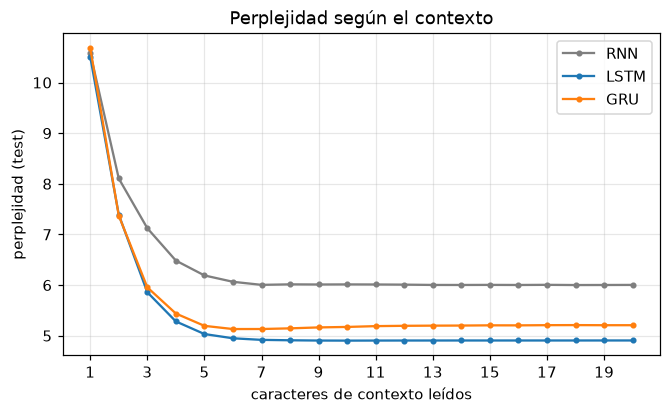

,1,2,3,5,7,10,15,20
RNN,10.5869,8.1056,7.1230,6.1901,6.0041,6.0131,6.0035,6.0031
LSTM,10.5128,7.3896,5.8581,5.0328,4.9176,4.9028,4.9054,4.9058
GRU,10.6817,7.3732,5.9547,5.1946,5.1319,5.1730,5.2046,5.2072


In [11]:
def pp_por_posicion(modelo):
    disp = next(modelo.parameters()).device
    modelo.eval(); suma = torch.zeros(20)
    with torch.no_grad():
        for i in range(0, len(Xte), 4096):
            logits = modelo(Xte[i:i + 4096].to(disp))
            suma += F.cross_entropy(logits.transpose(1, 2), Yte[i:i + 4096].to(disp), reduction='none').sum(0).cpu()
    return torch.exp(suma / len(Xte)).numpy()

pp_pos = {t: pp_por_posicion(m) for t, m in modelos_ref.items()}
plt.figure(figsize=(7, 3.8))
for t, v in pp_pos.items():
    plt.plot(range(1, 21), v, 'o-', ms=3, color=colores[t], label=t)
plt.xlabel('caracteres de contexto leídos'); plt.ylabel('perplejidad (test)'); plt.xticks(range(1, 21, 2))
plt.title('Perplejidad según el contexto'); plt.legend(); plt.show()
display(pd.DataFrame(pp_pos, index=range(1, 21)).loc[[1, 2, 3, 5, 7, 10, 15, 20]].T)

**Perplejidad en test según los caracteres de contexto leídos** (semilla 100):

| Contexto | 1 | 2 | 3 | 5 | 7 | 10 | 20 |
|---|---|---|---|---|---|---|---|
| RNN | 10,59 | 8,11 | 7,12 | 6,19 | 6,00 | 6,01 | 6,00 |
| LSTM | 10,51 | 7,39 | 5,86 | 5,03 | 4,92 | **4,90** | 4,91 |
| GRU | 10,68 | 7,37 | 5,95 | 5,19 | **5,13** | 5,17 | 5,21 |

* Con **1 carácter** las tres son iguales (≈ 10,5): no hay nada que recordar.
* **La ventaja aparece ya con 2–3 caracteres** (5,86 frente a 7,12 con 3): las redes con puertas **sacan más de los últimos caracteres**, porque combinan mejor el contexto inmediato.
* **Las tres dejan de mejorar hacia los 7–10 caracteres.** La LSTM sigue mejorando un poco hasta 10, y la GRU empeora levemente después de 7.

En este problema, la ventaja de la LSTM y la GRU **no viene de una memoria mucho más larga**, como en la Parte I, sino de modelar mejor el contexto corto. Con ventanas de 20 caracteres y 53 000 caracteres de entrenamiento, casi toda la información útil está en los últimos ≈ 7 caracteres (más o menos, la palabra actual y la anterior).

# 7. Generación de texto

Igual que en el Lab 2: se encadenan predicciones a partir de «the time traveller w», eligiendo siempre el carácter más probable (voraz) o muestreando con temperatura 0,7.

In [12]:
def generar(modelo, semilla, n=160, temperatura=None, gen=None):
    disp = next(modelo.parameters()).device
    s = preprocesar(semilla)
    modelo.eval()
    for _ in range(n):
        x = torch.tensor([[c2i[c] for c in s[-20:]]], device=disp)
        with torch.no_grad():
            logits = modelo(x)[0, -1].cpu()
        j = int(logits.argmax()) if temperatura is None else \
            int(torch.multinomial(F.softmax(logits / temperatura, dim=-1), 1, generator=gen))
        s += i2c[j]
    return s

muestras = {}
for t, m in modelos_ref.items():
    muestras[t] = {'voraz': generar(m, 'the time traveller w'),
                   'temperatura 0,7': generar(m, 'the time traveller w', temperatura=0.7, gen=torch.Generator().manual_seed(0))}
    print(f'--- {t} ---')
    for k, v in muestras[t].items():
        print(f'{k:16}', v)

--- RNN ---
voraz            the time traveller was a minute of the time traveller_ _it machine had a brown the time traveller_ _it machine had a brown the time traveller_ _it machine had a brown the time trav
temperatura 0,7  the time traveller walked and with of the whim it was always fool are along the intermnited his chair and dashed it_s sound round soot man smoking the line me_ with a lot the hout 


--- LSTM ---
voraz            the time traveller was a strange the time traveller the time traveller the time traveller the time traveller the time traveller the time traveller the time traveller the time trave
temperatura 0,7  the time traveller was his ded that of a moment the intermited_ and the other spieted not in since_ and made so that the whole gars here what it length_ and explain the medical man
--- GRU ---
voraz            the time traveller was the time traveller was the time traveller was the time traveller was the time traveller was the time traveller was the time traveller was the time traveller 
temperatura 0,7  the time traveller was his model and fars_ but dimensions_ and with black beginnings to the time traveller the genlaness_ the laboratory and this light_ and i was little went round


* **Voraz**: las tres entran en un **bucle** sobre la frase más repetida del libro («the time traveller»). La LSTM entra antes («the time traveller was a strange the time traveller the time traveller…»). Elegir siempre lo más probable no es una buena forma de generar, sea cual sea la red.
* **Con temperatura 0,7**: las tres producen palabras reales y fragmentos con aire del libro. La LSTM escribe «of a moment», «and explain the medical man» (el Médico es un personaje); la GRU, «his model», «dimensions», «the laboratory». Pero **ninguna tiene coherencia global**. La mejora de perplejidad (de ≈ 6 a ≈ 5 caracteres «posibles» en cada paso) se nota poco a simple vista.

# 8. Conclusiones

1. **Cambiar la RNN por una LSTM o una GRU sin reajustar nada empeora el resultado** (perplejidad 6,28 y 6,48 frente a 5,89 en validación): con 3–4 veces más parámetros sobreajustan desde la primera época, y la inicialización He de la RNN les perjudica.
2. **Optimizadas** (20 ejecuciones, test):
   * LSTM: **perplejidad 4,94 ± 0,05** y 52,34 % de exactitud;
   * GRU: **5,19 ± 0,02** y 51,42 %;
   * RNN *vanilla*: **5,96 ± 0,10** y 49,46 %.

   La LSTM reduce la perplejidad un 17 % y la GRU un 13 %.
3. **Lo que más importa al optimizarlas es regularizar**: dropout 0,5 (−0,76 y −0,87 de perplejidad en validación), seguido de la inicialización por defecto, la tasa 0,01 y la segunda capa. El tamaño oculto y el sesgo de olvido apenas cambian nada.
4. **Diferencias con la RNN**: las redes con puertas aprovechan mejor el contexto corto (ya con 2–3 caracteres), pero las tres dejan de mejorar hacia los 7–10 caracteres. Con ventanas de 20 y tan poco texto, la memoria larga de la LSTM no llega a marcar la diferencia, al contrario que en la Parte I. Además, la LSTM sobreajusta muchísimo antes (mejor época ≈ 1) y la GRU es la más estable.
5. **Coste**:
   * La **GRU** consigue tres cuartas partes de la mejora (−0,77 de perplejidad) con el doble de parámetros que la RNN (163 356) y 3 veces su tiempo por paso.
   * La **LSTM** final consigue algo más (−1,02) a cambio de 40 veces los parámetros (3,2 millones) y 22 veces el tiempo por paso en CPU. Eligió 512 unidades por una diferencia de 0,006 de perplejidad en validación, que no justifica ese coste.
   * Con el mismo tamaño (h = 256), la GRU cuesta 2,6 veces la RNN y la LSTM 3,5: la proporción GRU/LSTM (0,75) es exactamente el «25 % menos» de la teoría.

   Es lo que aconseja la teoría: **empezar con una GRU** y pasar a la LSTM solo si hace falta más memoria.
6. El texto generado mejora poco a simple vista: palabras reales y fragmentos del libro, pero ninguna coherencia global.

In [13]:
def a_lista(df):
    return [{'opcion': str(i)} | {k: (None if pd.isna(v) else float(v)) for k, v in fila.items()} for i, fila in df.iterrows()]

resultados = {
    'n': n, 'vocab': V, 'ventanas': [len(Xtr), len(Xva), len(Xte)],
    'parametros': {t: {k: int(v) for k, v in fila.items()} for t, fila in tabla_params.iterrows()},
    'exp0': a_lista(exp0),
    'optimizacion': {f'{t} · {e}': a_lista(df) for (t, e), df in optimizacion.items()},
    'configs': CONFIGS_FINALES,
    'final20': {t: {'test_acc': [f['test_acc'] for f in filas], 'test_pp': [f['test_pp'] for f in filas],
                    'mejor_epoca': [f['mejor_época'] for f in filas],
                    'curvas': {k: {'media': np.mean([f['hist'][k] for f in filas], 0).tolist(),
                                   'std': np.std([f['hist'][k] for f in filas], 0).tolist()}
                               for k in ('train_loss', 'val_loss', 'val_acc')}} for t, filas in finales.items()},
    'resumen20': {t: {k: float(v) for k, v in fila.items()} for t, fila in resumen20.iterrows()},
    'coste': {t: {k: float(v) for k, v in fila.items()} for t, fila in coste.iterrows()},
    'pp_posicion': {t: v.tolist() for t, v in pp_pos.items()},
    'muestras': muestras,
}
with open(LAB_DIR / 'resultados_lab3_caracteres.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1, default=float)
print('Resultados guardados en resultados_lab3_caracteres.json')

Resultados guardados en resultados_lab3_caracteres.json
